# Privacy–Security Trade-off in IDS Feature Space
## CICIDS2017 — Complete experiments S0–S4, E5, E6
 
### Scenarios:
- **S0** — Original feature space (baseline)
- **S1** — Context generalization (DestinationPort bucketing)
- **S2** — S1 + Temporal generalization (IAT/Active/Idle, bin 10ms)
- **S3** — S2 + High-risk feature suppression (OS fingerprinting signals)
- **S4** — Strict feature minimization (only 9 aggregates)
 
### Experiment E5 — Multi-level temporal generalization:
- **E5a** — Mild generalization (bin 1,000 μs = 1ms)
- **E5b** — Medium generalization (bin 10,000 μs = 10ms) ← same as S2
- **E5c** — Strong generalization (bin 100,000 μs = 100ms)
 
### Experiment E6 — Ablation by feature group:
- **E6a** — Remove only Time-based features (IAT, Active, Idle)
- **E6b** — Remove only Flag/Header features (SYN, RST, PSH, ACK, URG, Header Length)
- **E6c** — Remove only Bulk/Subflow/Window features
- **E6d** — Remove only Port/Context feature (DestinationPort)
- **E6e** — Remove only Packet Length features

## 0. Library imports

In [1]:
import pandas as pd
import numpy as np
import tensorflow as tf
from sklearn import metrics
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
warnings.filterwarnings('ignore')

print(f"TensorFlow: {tf.__version__}")
print(f"Pandas:     {pd.__version__}")


TensorFlow: 2.15.0
Pandas:     3.0.3


## 1. Loading data and models
⚠️ **Change PATH to your own path if it differs!**

In [2]:
PATH = r'C:\Users\AndjelaPC\Documents\ids-anonymization'

test_set  = pd.read_parquet(PATH + "/testset.parquet",  engine="pyarrow")
train_set = pd.read_parquet(PATH + "/trainset.parquet", engine="pyarrow")

print(f"Test set shape:  {test_set.shape}")
print(f"Train set shape: {train_set.shape}")

model = tf.keras.models.load_model(PATH + "/savedmodel/savedmodel")
print("\nModel učitan uspešno!")

attributenum  = len(test_set.columns) - 15
X_test_orig   = test_set.iloc[:, 0:attributenum].copy()
y_test        = test_set.iloc[:, -15:]
y_true        = np.argmax(y_test.to_numpy(), axis=1)

CLASS_NAMES       = list(y_test.columns)
CLASS_NAMES_CLEAN = [c.replace('Label_', '') for c in CLASS_NAMES]

print(f"\nBroj feature-a: {attributenum}")
print(f"Kolone (prve 5): {list(X_test_orig.columns[:5])}")
print(f"\nKlase: {CLASS_NAMES_CLEAN}")

Test set shape:  (565576, 92)
Train set shape: (2262300, 92)






Model učitan uspešno!

Broj feature-a: 77
Kolone (prve 5): ['DestinationPort', 'FlowDuration', 'TotalFwdPackets', 'TotalBackwardPackets', 'TotalLengthofFwdPackets']

Klase: ['BENIGN', 'Bot', 'DDoS', 'DoSGoldenEye', 'DoSHulk', 'DoSSlowhttptest', 'DoSslowloris', 'FTP-Patator', 'Heartbleed', 'Infiltration', 'PortScan', 'SSH-Patator', 'WebAttack-BruteForce', 'WebAttack-SqlInjection', 'WebAttack-XSS']


## 2. Defining feature groups
This is the central part — each group is precisely defined.

In [3]:
# ─── GRUPE FEATURE-A ─────────────────────────────────────────────────────────

# Sve IAT, Active i Idle vrednosti — temporal/behavioral fingerprinting rizik
GROUP_TEMPORAL = [
    'FlowIATMean', 'FlowIATStd', 'FlowIATMax', 'FlowIATMin',
    'FwdIATTotal', 'FwdIATMean', 'FwdIATStd', 'FwdIATMax', 'FwdIATMin',
    'BwdIATTotal', 'BwdIATMean', 'BwdIATStd', 'BwdIATMax', 'BwdIATMin',
    'ActiveMean',  'ActiveStd',  'ActiveMax',  'ActiveMin',
    'IdleMean',    'IdleStd',    'IdleMax',    'IdleMin'
]

# TCP flag i header feature-i — OS fingerprinting i TCP stack karakteristike
GROUP_FLAG_HEADER = [
    'FwdPSHFlags', 'BwdPSHFlags', 'FwdURGFlags', 'BwdURGFlags',
    'FwdHeaderLength', 'BwdHeaderLength',
    'FINFlagCount', 'SYNFlagCount', 'RSTFlagCount', 'PSHFlagCount',
    'ACKFlagCount', 'URGFlagCount', 'CWEFlagCount', 'ECEFlagCount'
]

# Bulk, Subflow i TCP Window feature-i — aplikacioni i OS profil
GROUP_BULK_SUBFLOW_WINDOW = [
    'FwdAvgBytes/Bulk', 'FwdAvgPackets/Bulk', 'FwdAvgBulkRate',
    'BwdAvgBytes/Bulk', 'BwdAvgPackets/Bulk', 'BwdAvgBulkRate',
    'SubflowFwdPackets', 'SubflowFwdBytes',
    'SubflowBwdPackets', 'SubflowBwdBytes',
    'Init_Win_bytes_forward', 'Init_Win_bytes_backward',
    'act_data_pkt_fwd', 'min_seg_size_forward'
]

# Port/Context — servisni fingerprinting
GROUP_PORT_CONTEXT = ['DestinationPort']

# Packet Length feature-i — behavioral fingerprint aplikacije
GROUP_PACKET_LENGTH = [
    'FwdPacketLengthMax', 'FwdPacketLengthMin',
    'FwdPacketLengthMean', 'FwdPacketLengthStd',
    'BwdPacketLengthMax', 'BwdPacketLengthMin',
    'BwdPacketLengthMean', 'BwdPacketLengthStd',
    'MinPacketLength', 'MaxPacketLength',
    'PacketLengthMean', 'PacketLengthStd', 'PacketLengthVariance',
    'AveragePacketSize', 'AvgFwdSegmentSize', 'AvgBwdSegmentSize'
]

# OS fingerprinting feature-i — koriste se u S3
GROUP_OS_FINGERPRINT = [
    'FwdHeaderLength', 'BwdHeaderLength',
    'SYNFlagCount', 'RSTFlagCount',
    'Init_Win_bytes_forward', 'Init_Win_bytes_backward',
    'min_seg_size_forward'
]

# Strict keep — samo ovi ostaju u S4
GROUP_STRICT_KEEP = [
    'FlowDuration', 'TotalFwdPackets', 'TotalBackwardPackets',
    'FlowBytes/s', 'FlowPackets/s', 'AveragePacketSize',
    'Down/UpRatio', 'FwdPackets/s', 'BwdPackets/s'
]

# Ispis pregleda
print("Grupe feature-a:")
print(f"  Temporal (IAT/Active/Idle):   {len(GROUP_TEMPORAL)} feature-a")
print(f"  Flag/Header:                  {len(GROUP_FLAG_HEADER)} feature-a")
print(f"  Bulk/Subflow/Window:          {len(GROUP_BULK_SUBFLOW_WINDOW)} feature-a")
print(f"  Port/Context:                 {len(GROUP_PORT_CONTEXT)} feature-a")
print(f"  Packet Length:                {len(GROUP_PACKET_LENGTH)} feature-a")
print(f"  OS Fingerprint (za S3):       {len(GROUP_OS_FINGERPRINT)} feature-a")
print(f"  Strict Keep (za S4):          {len(GROUP_STRICT_KEEP)} feature-a")

# Proveri koje kolone stvarno postoje u datasetu
all_cols = set(X_test_orig.columns)
print("\nProvera postojanja kolona:")
for name, grp in [('Temporal', GROUP_TEMPORAL), ('Flag/Header', GROUP_FLAG_HEADER),
                   ('Bulk/Sub/Win', GROUP_BULK_SUBFLOW_WINDOW),
                   ('Port', GROUP_PORT_CONTEXT), ('PacketLen', GROUP_PACKET_LENGTH)]:
    missing = [c for c in grp if c not in all_cols]
    present = [c for c in grp if c in all_cols]
    print(f"  {name}: {len(present)} prisutno, {len(missing)} nedostaje: {missing if missing else 'sve OK'}")

Grupe feature-a:
  Temporal (IAT/Active/Idle):   22 feature-a
  Flag/Header:                  14 feature-a
  Bulk/Subflow/Window:          14 feature-a
  Port/Context:                 1 feature-a
  Packet Length:                16 feature-a
  OS Fingerprint (za S3):       7 feature-a
  Strict Keep (za S4):          9 feature-a

Provera postojanja kolona:
  Temporal: 22 prisutno, 0 nedostaje: sve OK
  Flag/Header: 14 prisutno, 0 nedostaje: sve OK
  Bulk/Sub/Win: 14 prisutno, 0 nedostaje: sve OK
  Port: 1 prisutno, 0 nedostaje: sve OK
  PacketLen: 16 prisutno, 0 nedostaje: sve OK


## 3. Defining transformations

In [4]:
def zero_out(X, features):
    """Nuluj feature-e koji postoje u datasetu."""
    X2 = X.copy()
    for col in features:
        if col in X2.columns:
            X2[col] = 0
    return X2

def port_bucket(p):
    if p <= 1023:    return 0   # well-known
    elif p <= 49151: return 1   # registered
    else:            return 2   # dynamic

def apply_port_bucketing(X):
    X2 = X.copy()
    if 'DestinationPort' in X2.columns:
        X2['DestinationPort'] = X2['DestinationPort'].apply(port_bucket)
    return X2

def apply_temporal_gen(X, bin_us):
    X2 = X.copy()
    for col in GROUP_TEMPORAL:
        if col in X2.columns:
            X2[col] = (X2[col] / bin_us).round() * bin_us
    return X2

# ── S0–S4 ──────────────────────────────────────────────────────────────────
def apply_s0(X): return X.copy()
def apply_s1(X): return apply_port_bucketing(X)
def apply_s2(X): return apply_temporal_gen(apply_s1(X), 10_000)
def apply_s3(X): return zero_out(apply_s2(X), GROUP_OS_FINGERPRINT)
def apply_s4(X):
    X2 = apply_s3(X)
    for col in X2.columns:
        if col not in GROUP_STRICT_KEEP:
            X2[col] = 0
    return X2

# ── E5 — višestepena temporalna generalizacija ─────────────────────────────
def apply_e5a(X): return apply_temporal_gen(apply_s1(X),   1_000)  # 1ms
def apply_e5b(X): return apply_temporal_gen(apply_s1(X),  10_000)  # 10ms (=S2)
def apply_e5c(X): return apply_temporal_gen(apply_s1(X), 100_000)  # 100ms

# ── E6 — ablation po grupama feature-a ─────────────────────────────────────
# Svaki E6 scenario polazi od S0 (originala) i uklanja SAMO jednu grupu
# Cilj: videti koliko svaka grupa doprinosi modelu

def apply_e6a(X): return zero_out(X, GROUP_TEMPORAL)          # ukloni temporal
def apply_e6b(X): return zero_out(X, GROUP_FLAG_HEADER)       # ukloni flag/header
def apply_e6c(X): return zero_out(X, GROUP_BULK_SUBFLOW_WINDOW) # ukloni bulk/subflow/window
def apply_e6d(X): return zero_out(X, GROUP_PORT_CONTEXT)      # ukloni port
def apply_e6e(X): return zero_out(X, GROUP_PACKET_LENGTH)     # ukloni packet length

# ── Rečnici scenarija ──────────────────────────────────────────────────────
MAIN_SCENARIOS = {
    'S0 — Original':                apply_s0,
    'S1 — Context generalization':  apply_s1,
    'S2 — Temporal generalization': apply_s2,
    'S3 — High-risk suppression':   apply_s3,
    'S4 — Strict minimization':     apply_s4,
}

E5_SCENARIOS = {
    'E5a — Temporal (1ms bin)':   apply_e5a,
    'E5b — Temporal (10ms bin)':  apply_e5b,
    'E5c — Temporal (100ms bin)': apply_e5c,
}

E6_SCENARIOS = {
    'E6a — Remove Temporal':          (apply_e6a, 'Temporal (IAT/Active/Idle)', len(GROUP_TEMPORAL)),
    'E6b — Remove Flag/Header':        (apply_e6b, 'Flag/Header features',       len(GROUP_FLAG_HEADER)),
    'E6c — Remove Bulk/Subflow/Win':   (apply_e6c, 'Bulk/Subflow/Window',        len(GROUP_BULK_SUBFLOW_WINDOW)),
    'E6d — Remove Port/Context':       (apply_e6d, 'Port/Context (Dest. Port)',  len(GROUP_PORT_CONTEXT)),
    'E6e — Remove Packet Length':      (apply_e6e, 'Packet Length features',     len(GROUP_PACKET_LENGTH)),
}

print("Sve transformacije definisane!")

Sve transformacije definisane!


## 4. Evaluation function

In [5]:
def evaluate(name, X_transformed, y_true_labels):
    """Pokreni model i vrati metrike."""
    print(f"  Evaluacija: {name[:45]:<45}", end=" ")
    y_pred_raw = model.predict(X_transformed, verbose=0)
    y_pred     = np.argmax(y_pred_raw, axis=1)
    report     = metrics.classification_report(
        y_true_labels, y_pred,
        target_names=CLASS_NAMES_CLEAN,
        digits=4, output_dict=True, zero_division=0
    )
    acc  = metrics.accuracy_score(y_true_labels, y_pred)
    mf1  = report['macro avg']['f1-score']
    wf1  = report['weighted avg']['f1-score']
    print(f"Acc={acc:.4f}  MacroF1={mf1:.4f}  WeightedF1={wf1:.4f}")
    return {
        'name': name, 'accuracy': acc,
        'macro_f1': mf1, 'weighted_f1': wf1,
        'report': report,
        'cm': metrics.confusion_matrix(y_true_labels, y_pred)
    }

print("Funkcija za evaluaciju definisana.")

Funkcija za evaluaciju definisana.


## 5. Running S0–S4
⏳ May take 5–10 minutes.

In [6]:
print("="*70)
print("EVALUACIJA S0–S4")
print("="*70)
results_main = {}
for name, fn in MAIN_SCENARIOS.items():
    results_main[name] = evaluate(name, fn(X_test_orig), y_true)
print("\nS0–S4 završeno!")

EVALUACIJA S0–S4
  Evaluacija: S0 — Original                                 Acc=0.9962  MacroF1=0.7206  WeightedF1=0.9959
  Evaluacija: S1 — Context generalization                   Acc=0.9288  MacroF1=0.5024  WeightedF1=0.9460
  Evaluacija: S2 — Temporal generalization                  Acc=0.8777  MacroF1=0.2840  WeightedF1=0.8966
  Evaluacija: S3 — High-risk suppression                    Acc=0.7873  MacroF1=0.1082  WeightedF1=0.7562
  Evaluacija: S4 — Strict minimization                      Acc=0.3296  MacroF1=0.0355  WeightedF1=0.4267

S0–S4 završeno!


## 6. Running E5 — multi-level temporal generalization
⏳ May take 3–5 minutes.

In [7]:
print("="*70)
print("EVALUACIJA E5 — VIŠESTEPENA TEMPORALNA GENERALIZACIJA")
print("="*70)
results_e5 = {}
for name, fn in E5_SCENARIOS.items():
    results_e5[name] = evaluate(name, fn(X_test_orig), y_true)
print("\nE5 završeno!")

EVALUACIJA E5 — VIŠESTEPENA TEMPORALNA GENERALIZACIJA
  Evaluacija: E5a — Temporal (1ms bin)                      Acc=0.8777  MacroF1=0.2840  WeightedF1=0.8966
  Evaluacija: E5b — Temporal (10ms bin)                     Acc=0.8777  MacroF1=0.2840  WeightedF1=0.8966
  Evaluacija: E5c — Temporal (100ms bin)                    Acc=0.8777  MacroF1=0.2840  WeightedF1=0.8966

E5 završeno!


## 7. Running E6 — ablation by feature group
⏳ May take 5–8 minutes.

In [8]:
print("="*70)
print("EVALUACIJA E6 — ABLATION PO GRUPAMA FEATURE-A")
print("Polazna tačka: S0 (original), uklanja se JEDNA grupa u svakom scenariju")
print("="*70)
results_e6 = {}
for name, (fn, desc, n_features) in E6_SCENARIOS.items():
    print(f"\n  Grupa: {desc} ({n_features} feature-a)")
    results_e6[name] = evaluate(name, fn(X_test_orig), y_true)
    results_e6[name]['group_desc']    = desc
    results_e6[name]['n_features']    = n_features
print("\nE6 završeno!")

EVALUACIJA E6 — ABLATION PO GRUPAMA FEATURE-A
Polazna tačka: S0 (original), uklanja se JEDNA grupa u svakom scenariju

  Grupa: Temporal (IAT/Active/Idle) (22 feature-a)
  Evaluacija: E6a — Remove Temporal                         Acc=0.9430  MacroF1=0.4125  WeightedF1=0.9413

  Grupa: Flag/Header features (14 feature-a)
  Evaluacija: E6b — Remove Flag/Header                      Acc=0.8038  MacroF1=0.1203  WeightedF1=0.7221

  Grupa: Bulk/Subflow/Window (14 feature-a)
  Evaluacija: E6c — Remove Bulk/Subflow/Win                 Acc=0.8980  MacroF1=0.3343  WeightedF1=0.9054

  Grupa: Port/Context (Dest. Port) (1 feature-a)
  Evaluacija: E6d — Remove Port/Context                     Acc=0.9288  MacroF1=0.5024  WeightedF1=0.9460

  Grupa: Packet Length features (16 feature-a)
  Evaluacija: E6e — Remove Packet Length                    Acc=0.9431  MacroF1=0.4734  WeightedF1=0.9376

E6 završeno!


## 8. Tabular overview of all results

In [9]:
def make_summary(res_dict, extra_cols=None):
    rows = []
    for name, res in res_dict.items():
        r = res['report']
        row = {
            'Scenario':        name,
            'Accuracy':        round(res['accuracy'], 4),
            'Macro F1':        round(res['macro_f1'], 4),
            'Macro Precision': round(r['macro avg']['precision'], 4),
            'Macro Recall':    round(r['macro avg']['recall'], 4),
            'Weighted F1':     round(res['weighted_f1'], 4),
        }
        if extra_cols:
            for col in extra_cols:
                row[col] = res.get(col, '')
        rows.append(row)
    return pd.DataFrame(rows)

df_main = make_summary(results_main)
df_e5   = make_summary(results_e5)
df_e6   = make_summary(results_e6, extra_cols=['group_desc', 'n_features'])

s0_acc = results_main['S0 — Original']['accuracy']
s0_f1  = results_main['S0 — Original']['macro_f1']

# Dodaj kolone sa padom u odnosu na S0
df_main['Acc pad vs S0'] = (s0_acc - df_main['Accuracy']).round(4)
df_main['F1 pad vs S0']  = (s0_f1  - df_main['Macro F1']).round(4)

df_e6['Acc pad vs S0'] = (s0_acc - df_e6['Accuracy']).round(4)
df_e6['F1 pad vs S0']  = (s0_f1  - df_e6['Macro F1']).round(4)

print("\n" + "="*80)
print("TABELA 1 — GLAVNI SCENARIJI S0–S4")
print("="*80)
print(df_main.to_string(index=False))

print("\n" + "="*80)
print("TABELA 2 — E5: VIŠESTEPENA TEMPORALNA GENERALIZACIJA")
print("="*80)
print(df_e5.to_string(index=False))

print("\n" + "="*80)
print("TABELA 3 — E6: ABLATION PO GRUPAMA FEATURE-A (polazna tačka = S0)")
print("Interpretacija: veći pad = ta grupa je VAŽNIJA za model")
print("="*80)
print(df_e6[['Scenario','group_desc','n_features',
             'Accuracy','Macro F1','Acc pad vs S0','F1 pad vs S0']].to_string(index=False))


TABELA 1 — GLAVNI SCENARIJI S0–S4
                    Scenario  Accuracy  Macro F1  Macro Precision  Macro Recall  Weighted F1  Acc pad vs S0  F1 pad vs S0
               S0 — Original    0.9962    0.7206           0.8501        0.7047       0.9959        -0.0000        0.0000
 S1 — Context generalization    0.9288    0.5024           0.5370        0.6703       0.9460         0.0674        0.2182
S2 — Temporal generalization    0.8777    0.2840           0.2778        0.3544       0.8966         0.1185        0.4366
  S3 — High-risk suppression    0.7873    0.1082           0.1144        0.1150       0.7562         0.2089        0.6124
    S4 — Strict minimization    0.3296    0.0355           0.0502        0.0274       0.4267         0.6666        0.6851

TABELA 2 — E5: VIŠESTEPENA TEMPORALNA GENERALIZACIJA
                  Scenario  Accuracy  Macro F1  Macro Precision  Macro Recall  Weighted F1
  E5a — Temporal (1ms bin)    0.8777     0.284           0.2778        0.3544       0.89

In [10]:
# F1 po klasi za sve scenarije
def per_class_f1_df(res_dict):
    d = {}
    for name, res in res_dict.items():
        d[name] = {cls: res['report'].get(cls, {}).get('f1-score', 0.0)
                   for cls in CLASS_NAMES_CLEAN}
    return pd.DataFrame(d).T

pc_main = per_class_f1_df(results_main)
pc_e5   = per_class_f1_df(results_e5)
pc_e6   = per_class_f1_df(results_e6)

print("F1 PO KLASI — S0–S4")
print(pc_main.round(4).to_string())

print("\nF1 PO KLASI — E5")
print(pc_e5.round(4).to_string())

print("\nF1 PO KLASI — E6")
print(pc_e6.round(4).to_string())

F1 PO KLASI — S0–S4
                              BENIGN     Bot    DDoS  DoSGoldenEye  DoSHulk  DoSSlowhttptest  DoSslowloris  FTP-Patator  Heartbleed  Infiltration  PortScan  SSH-Patator  WebAttack-BruteForce  WebAttack-SqlInjection  WebAttack-XSS
S0 — Original                 0.9977  0.5441  0.9994        0.9855   0.9880           0.9779        0.9900       0.9972         0.8        0.1818    0.9964       0.9716                0.2478                     0.0         0.1324
S1 — Context generalization   0.9538  0.0000  0.9691        0.9761   0.8996           0.5584        0.7609       0.2153         0.8        0.1111    0.9900       0.1585                0.0823                     0.0         0.0615
S2 — Temporal generalization  0.9316  0.0000  0.8630        0.1011   0.6412           0.0581        0.3998       0.1193         0.0        0.0571    0.9864       0.0791                0.0232                     0.0         0.0000
S3 — High-risk suppression    0.8883  0.0000  0.4591        

## 9. Visualizations

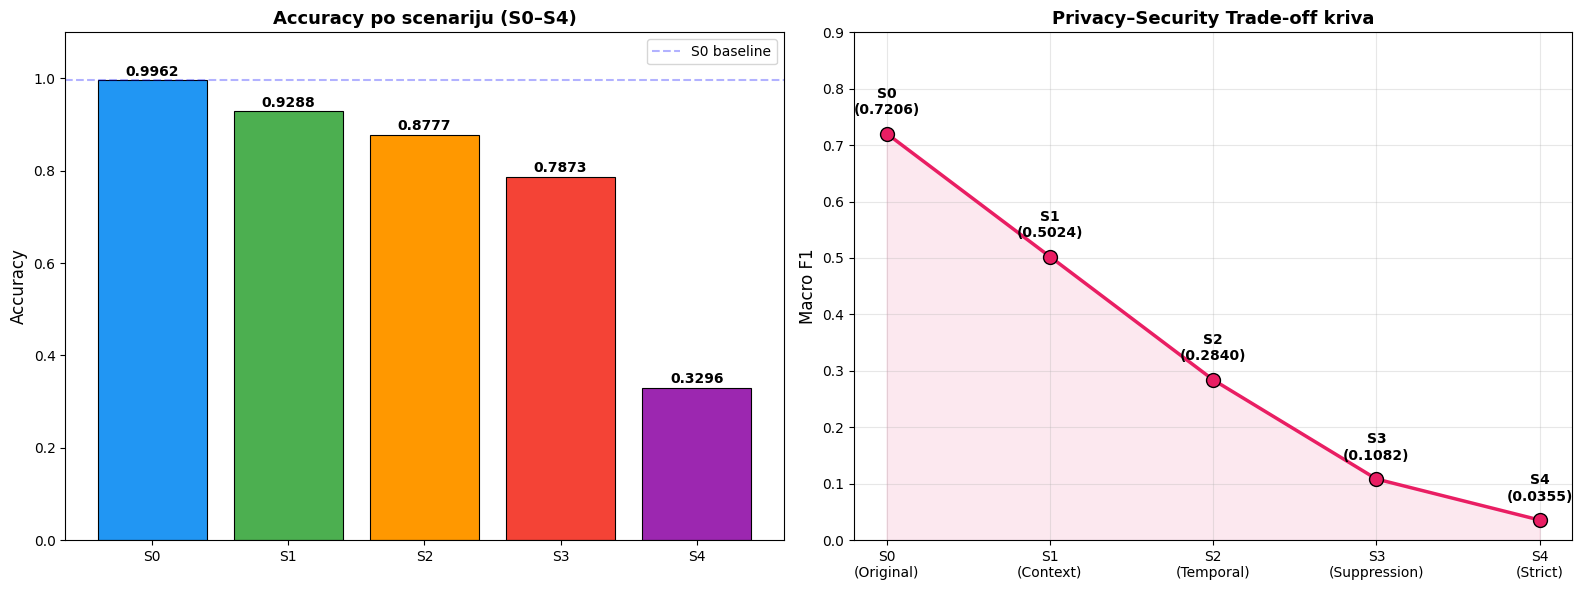

Sačuvano: graf1_tradeoff_kriva.png


In [11]:
# ── Graf 1: Trade-off kriva S0–S4 ────────────────────────────────────────────
labels_main = ['S0','S1','S2','S3','S4']
acc_main  = [results_main[n]['accuracy'] for n in MAIN_SCENARIOS]
mf1_main  = [results_main[n]['macro_f1'] for n in MAIN_SCENARIOS]

fig, axes = plt.subplots(1, 2, figsize=(16, 6))
colors = ['#2196F3','#4CAF50','#FF9800','#F44336','#9C27B0']

bars = axes[0].bar(labels_main, acc_main, color=colors, edgecolor='black', linewidth=0.8)
axes[0].set_ylim(0, 1.1)
axes[0].set_ylabel('Accuracy', fontsize=12)
axes[0].set_title('Accuracy po scenariju (S0–S4)', fontsize=13, fontweight='bold')
for bar, v in zip(bars, acc_main):
    axes[0].text(bar.get_x()+bar.get_width()/2, v+0.01, f'{v:.4f}',
                ha='center', fontsize=10, fontweight='bold')
axes[0].axhline(y=acc_main[0], color='blue', linestyle='--', alpha=0.3, label='S0 baseline')
axes[0].legend()

axes[1].plot([1,2,3,4,5], mf1_main, 'o-', color='#E91E63',
             linewidth=2.5, markersize=10, markeredgecolor='black')
axes[1].fill_between([1,2,3,4,5], mf1_main, alpha=0.1, color='#E91E63')
for i,(x,y,l) in enumerate(zip([1,2,3,4,5], mf1_main, labels_main)):
    axes[1].annotate(f'{l}\n({y:.4f})', (x,y), textcoords='offset points',
                    xytext=(0,14), ha='center', fontsize=10, fontweight='bold')
axes[1].set_xticks([1,2,3,4,5])
axes[1].set_xticklabels(['S0\n(Original)','S1\n(Context)','S2\n(Temporal)',
                          'S3\n(Suppression)','S4\n(Strict)'])
axes[1].set_ylabel('Macro F1', fontsize=12)
axes[1].set_title('Privacy–Security Trade-off kriva', fontsize=13, fontweight='bold')
axes[1].set_ylim(0, 0.9)
axes[1].grid(True, alpha=0.3)

plt.tight_layout()
plt.savefig('graf1_tradeoff_kriva.png', dpi=150, bbox_inches='tight')
plt.show()
print("Sačuvano: graf1_tradeoff_kriva.png")

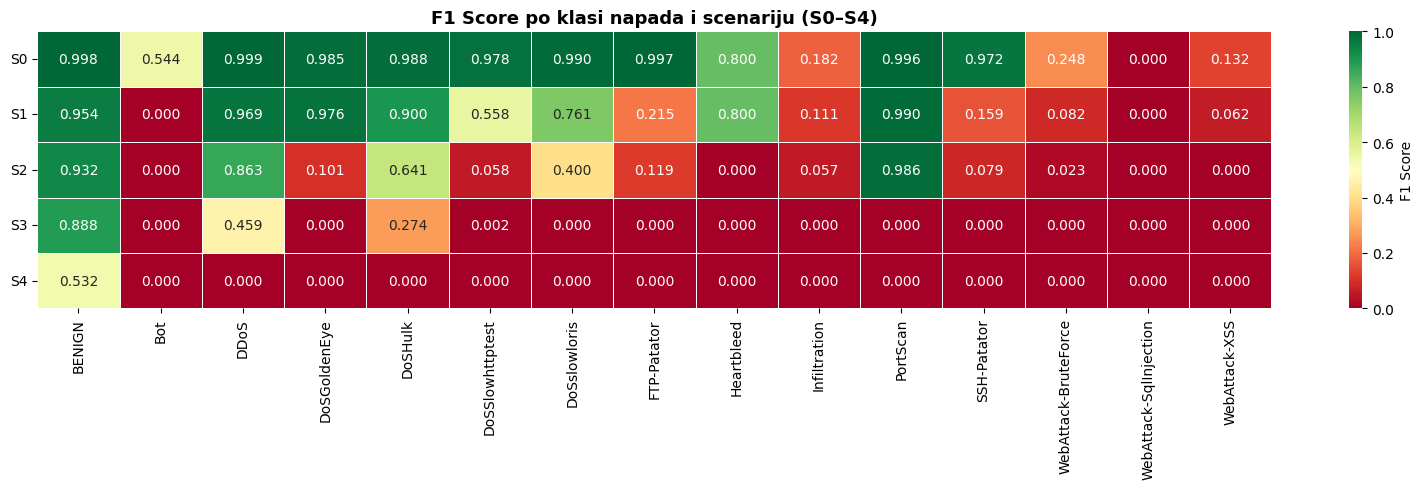

Sačuvano: graf2_f1_heatmap_s0s4.png


In [12]:
# ── Graf 2: F1 heatmap po klasi (S0–S4) ──────────────────────────────────────
fig, ax = plt.subplots(figsize=(16, 5))
sns.heatmap(pc_main, ax=ax, cmap='RdYlGn', vmin=0, vmax=1,
            annot=True, fmt='.3f', linewidths=0.4,
            cbar_kws={'label': 'F1 Score'},
            yticklabels=['S0','S1','S2','S3','S4'])
ax.set_title('F1 Score po klasi napada i scenariju (S0–S4)', fontsize=13, fontweight='bold')
ax.set_yticklabels(['S0','S1','S2','S3','S4'], rotation=0)
plt.tight_layout()
plt.savefig('graf2_f1_heatmap_s0s4.png', dpi=150, bbox_inches='tight')
plt.show()
print("Sačuvano: graf2_f1_heatmap_s0s4.png")

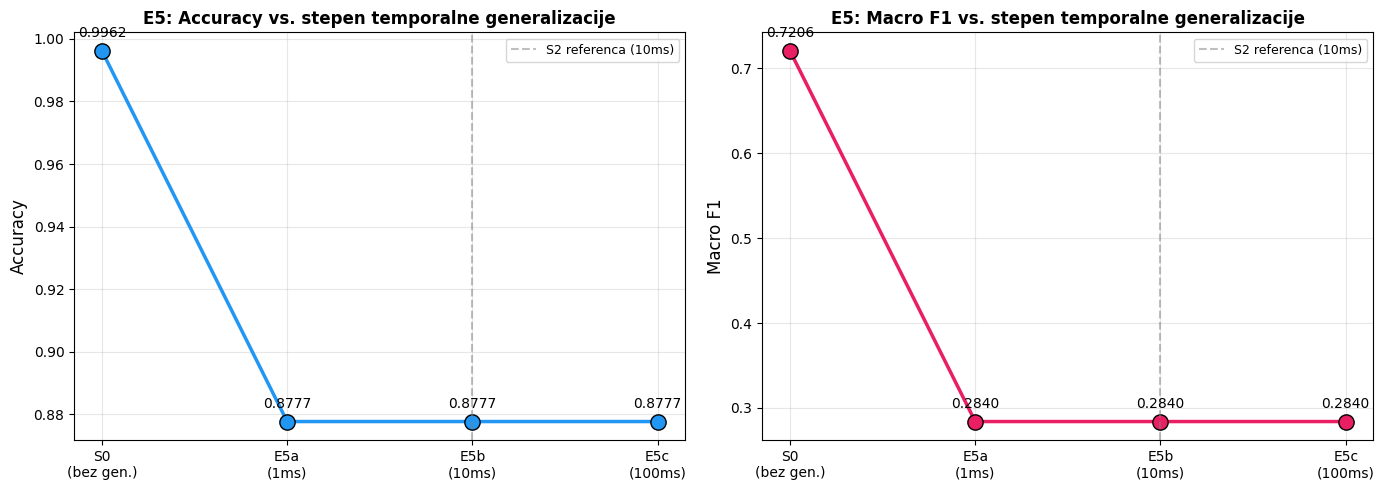

Sačuvano: graf3_e5_temporal.png


In [13]:
# ── Graf 3: E5 — višestepena temporalna generalizacija ────────────────────────
e5_labels = ['S0\n(bez gen.)', 'E5a\n(1ms)', 'E5b\n(10ms)', 'E5c\n(100ms)']
e5_acc = [results_main['S0 — Original']['accuracy']] + \
         [results_e5[n]['accuracy'] for n in E5_SCENARIOS]
e5_f1  = [results_main['S0 — Original']['macro_f1']] + \
         [results_e5[n]['macro_f1'] for n in E5_SCENARIOS]

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
x = [0, 1, 2, 3]

for ax, vals, ylabel, title, color in [
    (axes[0], e5_acc, 'Accuracy', 'E5: Accuracy vs. stepen temporalne generalizacije', '#2196F3'),
    (axes[1], e5_f1,  'Macro F1', 'E5: Macro F1 vs. stepen temporalne generalizacije',  '#E91E63')
]:
    ax.plot(x, vals, 'o-', color=color, linewidth=2.5, markersize=11, markeredgecolor='black')
    ax.set_xticks(x)
    ax.set_xticklabels(e5_labels, fontsize=10)
    ax.set_ylabel(ylabel, fontsize=12)
    ax.set_title(title, fontsize=12, fontweight='bold')
    ax.grid(True, alpha=0.3)
    for xi, yi in zip(x, vals):
        ax.annotate(f'{yi:.4f}', (xi, yi), textcoords='offset points',
                   xytext=(0, 10), ha='center', fontsize=10)
    # Označi referentni bin (10ms = S2)
    ax.axvline(x=2, color='gray', linestyle='--', alpha=0.5, label='S2 referenca (10ms)')
    ax.legend(fontsize=9)

plt.tight_layout()
plt.savefig('graf3_e5_temporal.png', dpi=150, bbox_inches='tight')
plt.show()
print("Sačuvano: graf3_e5_temporal.png")

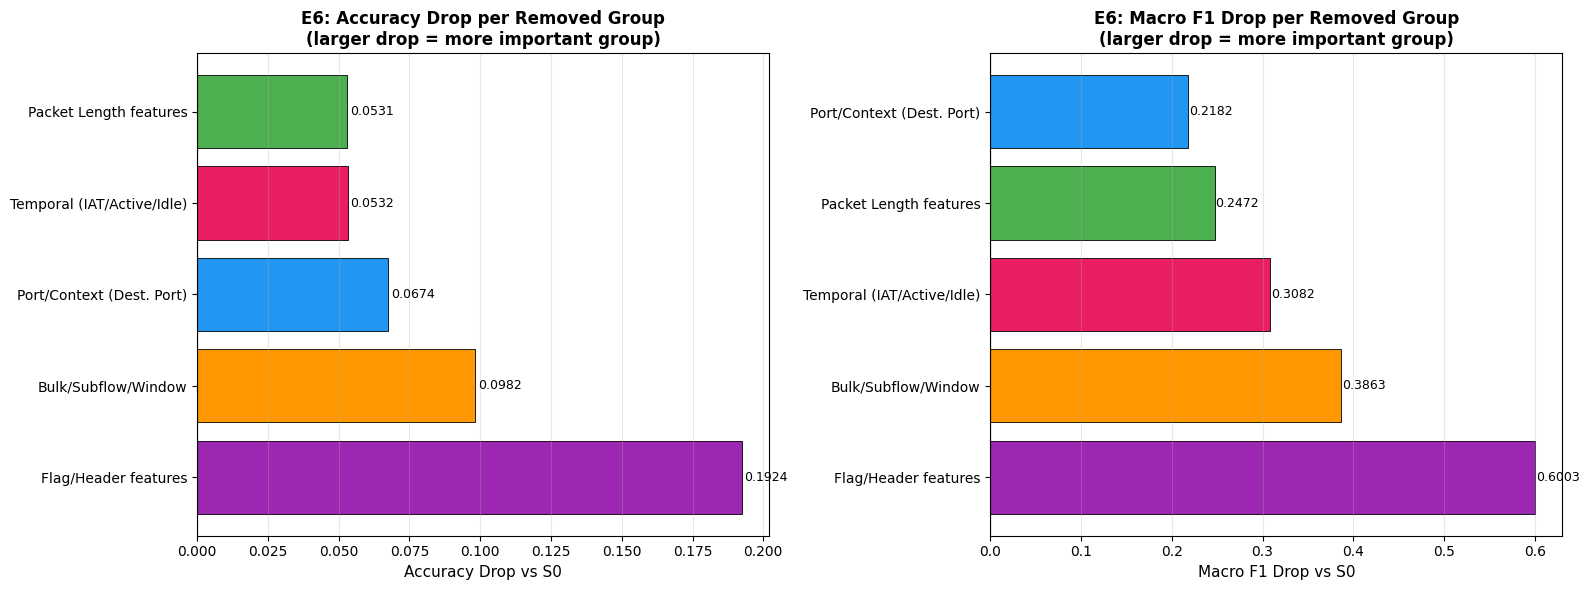

Sačuvano: graf4_e6_ablation.png


In [14]:
# ── Graf 4: E6 — ablation — doprinos svake grupe feature-a ───────────────────
# Logika: veći PAD = ta grupa je VAŽNIJA za model
e6_names  = list(E6_SCENARIOS.keys())
e6_labels = [results_e6[n]['group_desc'] for n in e6_names]
e6_acc_drop = [s0_acc - results_e6[n]['accuracy'] for n in e6_names]
e6_f1_drop  = [s0_f1  - results_e6[n]['macro_f1'] for n in e6_names]
e6_nfeat    = [results_e6[n]['n_features'] for n in e6_names]
fig, axes = plt.subplots(1, 2, figsize=(16, 6))
colors_e6 = ['#E91E63','#9C27B0','#FF9800','#2196F3','#4CAF50']
for ax, drops, title, xlabel in [
    (axes[0], e6_acc_drop, 'E6: Accuracy Drop per Removed Group\n(larger drop = more important group)', 'Accuracy Drop vs S0'),
    (axes[1], e6_f1_drop,  'E6: Macro F1 Drop per Removed Group\n(larger drop = more important group)', 'Macro F1 Drop vs S0')
]:
    sorted_pairs = sorted(zip(drops, e6_labels, colors_e6), reverse=True)
    s_drops, s_labels, s_colors = zip(*sorted_pairs)
    bars = ax.barh(range(len(s_labels)), s_drops, color=s_colors, edgecolor='black', linewidth=0.6)
    ax.set_yticks(range(len(s_labels)))
    ax.set_yticklabels(s_labels, fontsize=10)
    ax.set_xlabel(xlabel, fontsize=11)
    ax.set_title(title, fontsize=12, fontweight='bold')
    ax.grid(axis='x', alpha=0.3)
    ax.axvline(x=0, color='black', linewidth=0.8)
    for bar, v in zip(bars, s_drops):
        ax.text(v + 0.001, bar.get_y()+bar.get_height()/2,
               f'{v:.4f}', va='center', fontsize=9)
plt.tight_layout()
plt.savefig('graf4_e6_ablation.png', dpi=150, bbox_inches='tight')
plt.show()
print("Sačuvano: graf4_e6_ablation.png")

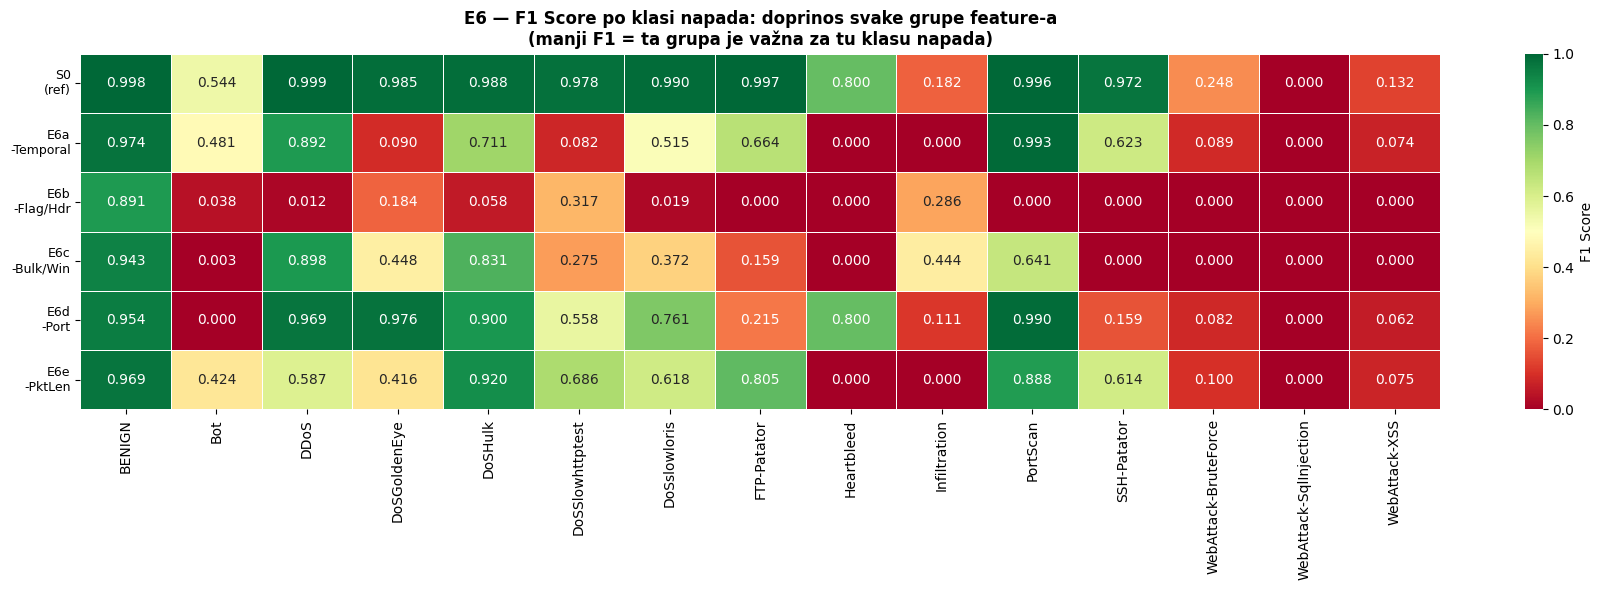

Sačuvano: graf5_e6_heatmap.png


In [15]:
# ── Graf 5: E6 F1 heatmap po klasi ───────────────────────────────────────────
e6_short = ['S0\n(ref)', 'E6a\n-Temporal', 'E6b\n-Flag/Hdr',
            'E6c\n-Bulk/Win', 'E6d\n-Port', 'E6e\n-PktLen']

# Kombinuj S0 i E6 rezultate
pc_e6_full = pd.concat([
    pc_main.iloc[[0]].rename(index={'S0 — Original': 'S0 (referenca)'}),
    pc_e6
])

fig, ax = plt.subplots(figsize=(18, 6))
sns.heatmap(pc_e6_full, ax=ax, cmap='RdYlGn', vmin=0, vmax=1,
            annot=True, fmt='.3f', linewidths=0.4,
            cbar_kws={'label': 'F1 Score'},
            yticklabels=e6_short)
ax.set_title('E6 — F1 Score po klasi napada: doprinos svake grupe feature-a\n'
             '(manji F1 = ta grupa je važna za tu klasu napada)', fontsize=12, fontweight='bold')
ax.set_yticklabels(e6_short, rotation=0, fontsize=9)
plt.tight_layout()
plt.savefig('graf5_e6_heatmap.png', dpi=150, bbox_inches='tight')
plt.show()
print("Sačuvano: graf5_e6_heatmap.png")

## 10. Final conclusions and interpretation

In [16]:
print("="*75)
print("FINALNI ZAKLJUČCI")
print("="*75)

print("\n── S0–S4 TRADE-OFF ──")
for name, res in results_main.items():
    pad_acc = s0_acc - res['accuracy']
    pad_f1  = s0_f1  - res['macro_f1']
    print(f"  {name[:40]:<40}  Acc={res['accuracy']:.4f}  F1={res['macro_f1']:.4f}"
          f"  (pad: Acc={pad_acc:+.4f}, F1={pad_f1:+.4f})")

print("\n── E5: GRADUELNOST TEMPORALNE GENERALIZACIJE ──")
for name, res in results_e5.items():
    print(f"  {name:<35}  Acc={res['accuracy']:.4f}  F1={res['macro_f1']:.4f}")

print("\n── E6: RANG VAŽNOSTI GRUPA FEATURE-A (po padu F1) ──")
e6_ranked = sorted(
    [(n, results_e6[n]['group_desc'], results_e6[n]['n_features'],
      s0_f1 - results_e6[n]['macro_f1'],
      s0_acc - results_e6[n]['accuracy'])
     for n in E6_SCENARIOS],
    key=lambda x: x[3], reverse=True
)
print(f"  {'Rang':<5} {'Grupa':<30} {'N feat':<8} {'Pad F1':<10} {'Pad Acc'}")
print("  " + "-"*65)
for i, (name, desc, n, df1, dacc) in enumerate(e6_ranked, 1):
    print(f"  {i:<5} {desc:<30} {n:<8} {df1:<10.4f} {dacc:.4f}")

print("\n── INTERPRETACIJA E6 ──")
print("  Rang 1 = najvažnija grupa za model (najveći pad kada se ukloni)")
print("  Rang 5 = najmanje bitna grupa (najmanji pad kada se ukloni)")
print("  Ovo direktno odgovara na pitanje: koja porodica feature-a")
print("  je najkritičnija i koja se može transformisati uz najmanji gubitak.")

# Najvulnerabilnije klase u S4
f1_drop_s4 = pc_main.loc['S0 — Original'] - pc_main.loc['S4 — Strict minimization']
print("\n── TOP 5 NAJVULNERABILNIJIH KLASA (pad F1 od S0 do S4) ──")
print(f1_drop_s4.sort_values(ascending=False).head(5).round(4).to_string())

print("\n" + "="*75)
print("Svi grafici sačuvani u folderu:")
print("  graf1_tradeoff_kriva.png")
print("  graf2_f1_heatmap_s0s4.png")
print("  graf3_e5_temporal.png")
print("  graf4_e6_ablation.png")
print("  graf5_e6_heatmap.png")
print("="*75)

FINALNI ZAKLJUČCI

── S0–S4 TRADE-OFF ──
  S0 — Original                             Acc=0.9962  F1=0.7206  (pad: Acc=+0.0000, F1=+0.0000)
  S1 — Context generalization               Acc=0.9288  F1=0.5024  (pad: Acc=+0.0674, F1=+0.2182)
  S2 — Temporal generalization              Acc=0.8777  F1=0.2840  (pad: Acc=+0.1185, F1=+0.4366)
  S3 — High-risk suppression                Acc=0.7873  F1=0.1082  (pad: Acc=+0.2089, F1=+0.6124)
  S4 — Strict minimization                  Acc=0.3296  F1=0.0355  (pad: Acc=+0.6666, F1=+0.6852)

── E5: GRADUELNOST TEMPORALNE GENERALIZACIJE ──
  E5a — Temporal (1ms bin)             Acc=0.8777  F1=0.2840
  E5b — Temporal (10ms bin)            Acc=0.8777  F1=0.2840
  E5c — Temporal (100ms bin)           Acc=0.8777  F1=0.2840

── E6: RANG VAŽNOSTI GRUPA FEATURE-A (po padu F1) ──
  Rang  Grupa                          N feat   Pad F1     Pad Acc
  -----------------------------------------------------------------
  1     Flag/Header features           14       

In [17]:
model.summary()

Model: "sequential"
_________________________________________________________________
 Layer (type)                Output Shape              Param #   
 dense (Dense)               (None, 90)                7020      
                                                                 
 dense_1 (Dense)             (None, 50)                4550      
                                                                 
 dense_2 (Dense)             (None, 15)                765       
                                                                 
Total params: 12335 (48.18 KB)
Trainable params: 12335 (48.18 KB)
Non-trainable params: 0 (0.00 Byte)
_________________________________________________________________


In [18]:
# ── Provera E5: da li rounding zaista menja vrednosti ─────────────────────

import numpy as np

# Uzmi mali uzorak originalnih IAT vrednosti
sample = X_test_orig['FlowIATMean'].head(20).values
print("ORIGINALNE vrednosti FlowIATMean (prve 20):")
print(sample)

# Primeni rounding za svaki nivo
for bin_us in [1_000, 10_000, 100_000]:
    rounded = (sample / bin_us).round() * bin_us
    print(f"\nNakon roundinga na {bin_us} μs:")
    print(rounded)
    n_changed = np.sum(sample != rounded)
    print(f"  Promenilo se: {n_changed}/20 vrednosti")

# Provjeri da li su E5a i E5c zaista razlicite od S2
print("\n── Poređenje distribucija ──────────────────────────────────────")
for bin_us, name in [(1_000, 'E5a (1ms)'), (10_000, 'E5b/S2 (10ms)'), (100_000, 'E5c (100ms)')]:
    col = X_test_orig['FlowIATMean']
    rounded = (col / bin_us).round() * bin_us
    n_unique_orig = col.nunique()
    n_unique_round = rounded.nunique()
    print(f"{name}: originalno {n_unique_orig} unikatnih → posle roundinga {n_unique_round} unikatnih")

ORIGINALNE vrednosti FlowIATMean (prve 20):
[7.6388875e-07 7.2222213e-07 7.3333325e-07 1.6117997e-02 4.6666662e-07
 1.1854362e-04 6.6388878e-07 3.3331811e-02 6.1249989e-06 1.4166665e-07
 7.0833323e-07 2.2771665e-04 1.6880553e-04 5.8584905e-04 1.4166665e-07
 8.3409628e-04 6.6666661e-07 1.3333332e-07 9.7603267e-03 4.2042015e-03]

Nakon roundinga na 1000 μs:
[0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0.]
  Promenilo se: 20/20 vrednosti

Nakon roundinga na 10000 μs:
[0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0.]
  Promenilo se: 20/20 vrednosti

Nakon roundinga na 100000 μs:
[0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0.]
  Promenilo se: 20/20 vrednosti

── Poređenje distribucija ──────────────────────────────────────
E5a (1ms): originalno 270479 unikatnih → posle roundinga 1 unikatnih
E5b/S2 (10ms): originalno 270479 unikatnih → posle roundinga 1 unikatnih
E5c (100ms): originalno 270479 unikatnih → posle roundinga 1 unikatnih
